# Day 27 — Random Forests, Bagging, and Responsible Interpretation

**Dataset required:** `titanic.csv` in the same folder as this notebook.

This notebook follows the task sheet and uses the six requested features:
`pclass`, `sex_male`, `age`, `sibsp`, `parch`, `fare`; target: `survived`.

> Run cells from top to bottom. Numerical results depend on the supplied CSV and your installed scikit-learn version. Do not invent or hard-code scores.

## Setup

In [7]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

RANDOM_STATE = 42

## Data preparation

In [8]:
df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()

required_columns = ["pclass", "sex", "age", "sibsp", "parch", "fare", "survived"]
missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df[required_columns].copy()
df["sex_male"] = df["sex"].astype(str).str.strip().str.lower().eq("male").astype(int)

# Group-wise median age imputation, as required by the task sheet.
df["age"] = df.groupby(["pclass", "sex_male"])["age"].transform(
    lambda s: s.fillna(s.median())
)
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"
df = df.dropna(subset=[target, *features]).copy()
df[target] = df[target].astype(int)

X = df[features]
y = df[target]
print("Dataset rows after cleaning:", len(df))
print(f"Survival rate: {y.mean():.4f} ({y.mean()*100:.2f}%)")
display(df[features + [target]].isna().sum().to_frame("missing values"))

Dataset rows after cleaning: 1000
Survival rate: 0.4400 (44.00%)


,missing values
pclass,0
sex_male,0
age,0
sibsp,0
parch,0
fare,0
survived,0


### Markdown — Data preparation

The CSV column names are standardized, `sex` is encoded as `sex_male` (1 = male, 0 = not male), missing ages are imputed by passenger class and sex group, and missing fares by the overall median. The code prints the cleaned row count and survival rate. The sheet says not to invent `embarked`, so it is not used.

**Real life:** Similar to cleaning customer or service records before making predictions. Missing values need a consistent treatment and categories often need numeric encoding.

## Train/test split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Train survival rate:", round(y_train.mean(), 4))
print("Test survival rate:", round(y_test.mean(), 4))

Training rows: 800
Testing rows: 200
Train survival rate: 0.44
Test survival rate: 0.44


### Markdown — Train/test split

An 80/20 stratified split keeps approximately the same survival proportion in both sets. `random_state=42` makes the split reproducible. Keep the test set out of model selection wherever possible.

**Real life:** Training data is practice; test data is a final exam on examples the model did not learn from.

# Task 01 — Bootstrap samples by hand
**Lookup / concept answer:** Bootstrap sampling draws the same number of rows *with replacement*. A row can be drawn multiple times, and some rows may not be selected. Duplicates and absent rows are expected because every draw is independent.

Original training rows: 800
Bootstrap rows: 800
Unique original rows represented: 502
Rows never selected: 298
Example original row index selected more than once: 755


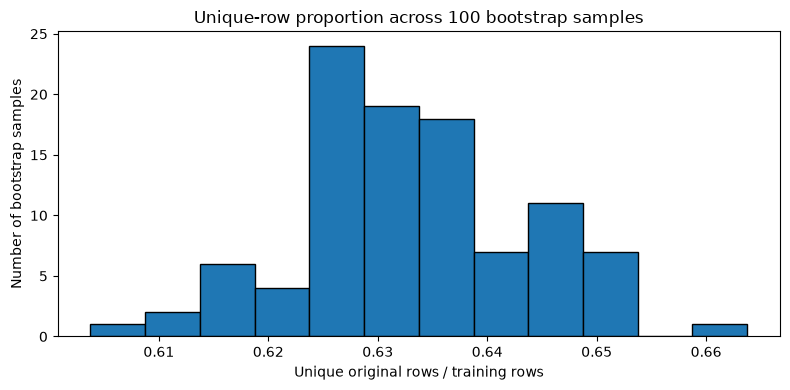

In [10]:
def bootstrap_sample(X, y, rng):
    # Sample positional row indices with replacement.
    indices = rng.integers(0, len(X), size=len(X))
    X_boot = X.iloc[indices].reset_index(drop=True)
    y_boot = y.iloc[indices].reset_index(drop=True)
    return X_boot, y_boot, indices

rng = np.random.default_rng(7)
X_boot, y_boot, indices = bootstrap_sample(X_train, y_train, rng)

unique_count = len(np.unique(indices))
never_selected = len(X_train) - unique_count
duplicates = [idx for idx, count in Counter(indices).items() if count > 1]

print("Original training rows:", len(X_train))
print("Bootstrap rows:", len(X_boot))
print("Unique original rows represented:", unique_count)
print("Rows never selected:", never_selected)
print("Example original row index selected more than once:",
      duplicates[0] if duplicates else "No duplicate in this draw")

unique_proportions = []
for _ in range(100):
    _, _, sample_indices = bootstrap_sample(X_train, y_train, rng)
    unique_proportions.append(len(np.unique(sample_indices)) / len(X_train))

plt.figure(figsize=(8, 4))
plt.hist(unique_proportions, bins=12, edgecolor="black")
plt.title("Unique-row proportion across 100 bootstrap samples")
plt.xlabel("Unique original rows / training rows")
plt.ylabel("Number of bootstrap samples")
plt.tight_layout()
plt.show()

### Markdown — Task 01 logic and answer

The helper samples positional indices, then uses those same indices for both `X` and `y` so features and labels stay aligned. One sample reports the original size, bootstrap size, unique rows, rows missed, and a duplicated index. A histogram summarizes the unique-row fraction over 100 samples.

**Real life:** A poll or audit repeatedly draws records from a pool; with replacement, some records get picked twice while others are skipped. Different samples create slightly different training experiences.

# Task 02 — Make five trees disagree
**Lookup / concept answers:**
1. Trees differ because each sees a different bootstrap sample and can learn different split rules.
2. Disagreement is not always bad; it reveals unstable or ambiguous cases.
3. A 5–0 vote is generally less fragile than a 3–2 vote, although agreement does not guarantee correctness.

In [11]:
rng = np.random.default_rng(202)
trees5 = []
for i in range(5):
    Xb, yb, _ = bootstrap_sample(X_train, y_train, rng)
    tree = DecisionTreeClassifier(max_depth=5, random_state=100 + i)
    tree.fit(Xb, yb)
    trees5.append(tree)

X_first20 = X_test.iloc[:20]
y_first20 = y_test.iloc[:20]
pred5 = np.column_stack([tree.predict(X_first20) for tree in trees5])

results5 = pd.DataFrame(pred5, columns=[f"tree_{i+1}" for i in range(5)])
results5.insert(0, "passenger_index", X_first20.index.to_numpy())
results5["survive_votes"] = pred5.sum(axis=1)
results5["not_survive_votes"] = 5 - results5["survive_votes"]
results5["majority_prediction"] = (pred5.mean(axis=1) >= 0.5).astype(int)
results5["true_label"] = y_first20.to_numpy()
results5["disagreement"] = (pred5.min(axis=1) != pred5.max(axis=1))
display(results5)

disagree = results5[results5["disagreement"]]
print("Passengers with disagreement:", len(disagree))
print("Disagreement percentage:", round(100 * results5["disagreement"].mean(), 2), "%")
print("At least three examples (if available):")
display(disagree.head(3)[[
    "passenger_index", "survive_votes", "not_survive_votes",
    "majority_prediction", "true_label"
]])

,passenger_index,tree_1,tree_2,tree_3,tree_4,tree_5,survive_votes,not_survive_votes,majority_prediction,true_label,disagreement
0,262,1,1,1,1,1,5,0,1,1,False
1,819,0,0,0,0,0,0,5,0,0,False
2,997,1,1,1,1,1,5,0,1,1,False
3,341,0,0,0,0,0,0,5,0,1,False
4,546,1,1,1,1,1,5,0,1,1,False
5,521,0,0,0,1,0,1,4,0,1,True
6,914,0,0,0,0,0,0,5,0,0,False
7,71,1,1,1,1,1,5,0,1,1,False
8,247,1,1,1,1,1,5,0,1,1,False
9,98,0,0,0,1,0,1,4,0,1,True


Passengers with disagreement: 5
Disagreement percentage: 25.0 %
At least three examples (if available):


,passenger_index,survive_votes,not_survive_votes,majority_prediction,true_label
5,521,1,4,0,1
9,98,1,4,0,1
12,64,1,4,0,0


### Markdown — Task 02 logic and answer

Five depth-5 trees are trained on different bootstrap samples and predict the same 20 test passengers. The table includes each tree's prediction, the survival/non-survival vote count, majority prediction, true label, and disagreement flag. The percentage is the number of passengers with mixed votes divided by 20.

**Real life:** Five reviewers may assess the same application differently because they saw different examples. A close vote signals a borderline case worth reviewing.

# Task 03 — Implement a bagged forest manually
**Lookup / concept answer:** Bagging trains models on bootstrap samples and aggregates their predictions. Classification commonly uses majority vote; probabilities can be averaged. Averaging diverse trees often reduces variance compared with relying on one tree.

,model,accuracy,roc_auc
0,Single depth-5 tree,0.750,0.811029
1,Manual bagging (100 trees),0.755,0.875913


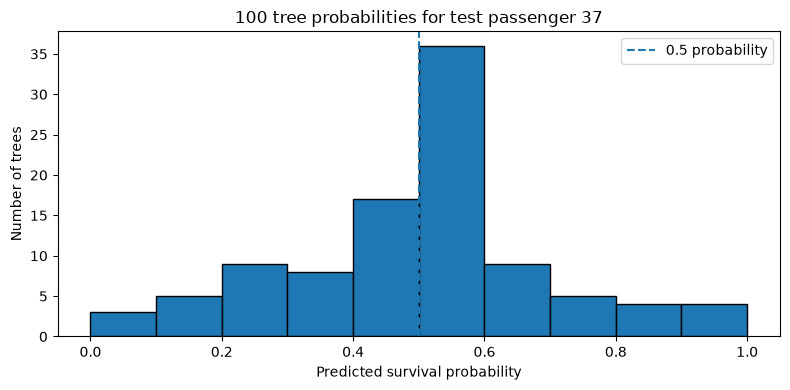

Selected passenger mean survival probability: 0.4993


In [12]:
rng = np.random.default_rng(303)
trees100 = []
for i in range(100):
    Xb, yb, _ = bootstrap_sample(X_train, y_train, rng)
    tree = DecisionTreeClassifier(max_depth=5, random_state=1000 + i)
    tree.fit(Xb, yb)
    trees100.append(tree)

tree_predictions = np.array([tree.predict(X_test) for tree in trees100])
tree_probabilities = np.array([tree.predict_proba(X_test)[:, 1] for tree in trees100])

majority_vote = (tree_predictions.mean(axis=0) >= 0.5).astype(int)
mean_probability = tree_probabilities.mean(axis=0)

single_tree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
single_tree.fit(X_train, y_train)
single_pred = single_tree.predict(X_test)
single_prob = single_tree.predict_proba(X_test)[:, 1]

def metric_row(name, pred, prob):
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob)
    }

manual_metrics = pd.DataFrame([
    metric_row("Single depth-5 tree", single_pred, single_prob),
    metric_row("Manual bagging (100 trees)", majority_vote, mean_probability)
])
display(manual_metrics)

# Choose a test passenger whose average probability is closest to 0.5.
close_idx = int(np.argmin(np.abs(mean_probability - 0.5)))
plt.figure(figsize=(8, 4))
plt.hist(tree_probabilities[:, close_idx], bins=np.linspace(0, 1, 11), edgecolor="black")
plt.axvline(0.5, linestyle="--", label="0.5 probability")
plt.title(f"100 tree probabilities for test passenger {X_test.index[close_idx]}")
plt.xlabel("Predicted survival probability")
plt.ylabel("Number of trees")
plt.legend()
plt.tight_layout()
plt.show()
print("Selected passenger mean survival probability:", round(mean_probability[close_idx], 4))

### Markdown — Task 03 logic and answer

A loop trains 100 depth-5 trees, each on a fresh bootstrap sample. Their class predictions are combined by majority vote, while survival probabilities are averaged. The resulting metrics are compared with one depth-5 tree trained on all training rows. The histogram shows how individual trees vary for a passenger whose average probability is nearest 0.5.

**Real life:** A committee averages multiple independent assessments instead of trusting one person's potentially noisy judgment.

# Task 04 — Compare a tree, bagging, and a Random Forest
**Lookup / concept answers:** A Random Forest differs from plain bagging because it also samples a random subset of features at each split, encouraging tree diversity. The best mean ROC-AUC and most stable model must be identified from your output, not assumed in advance. One split or experiment does not prove universal superiority.

,model,accuracy,roc_auc,training_seconds
0,Single tree,0.750,0.811029,0.003792
1,Manual bagging (100),0.765,0.882305,0.198306
2,Random Forest (200),0.780,0.878145,0.246705


,model,mean,std
0,Manual bagging,0.863476,0.015258
1,Random Forest,0.870306,0.011868
2,Single tree,0.819434,0.026842


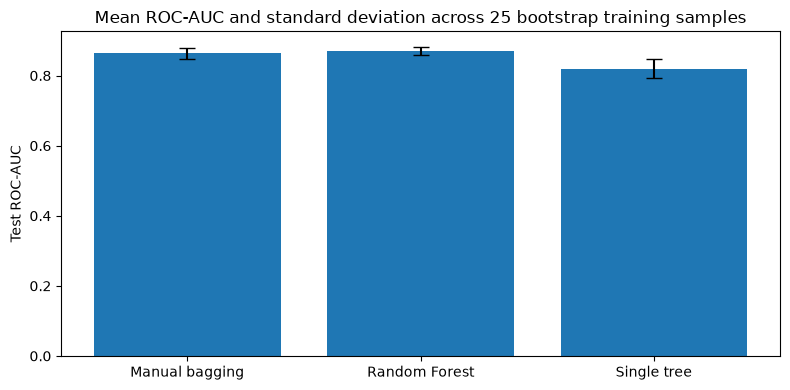

In [13]:
def fit_manual_bagging(Xtr, ytr, seed, n_trees=100, max_depth=5):
    rng = np.random.default_rng(seed)
    models = []
    for i in range(n_trees):
        Xb, yb, _ = bootstrap_sample(Xtr, ytr, rng)
        model = DecisionTreeClassifier(max_depth=max_depth, random_state=seed + i + 1)
        model.fit(Xb, yb)
        models.append(model)
    return models

def manual_predict(models, Xeval):
    preds = np.array([m.predict(Xeval) for m in models])
    probs = np.array([m.predict_proba(Xeval)[:, 1] for m in models])
    return (preds.mean(axis=0) >= 0.5).astype(int), probs.mean(axis=0)

# One-run benchmark on the prescribed split, including training time.
bench = []
t0 = time.perf_counter()
tree4 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
tree_time = time.perf_counter() - t0
bench.append({**metric_row("Single tree", tree4.predict(X_test),
                          tree4.predict_proba(X_test)[:, 1]), "training_seconds": tree_time})

t0 = time.perf_counter()
bag4 = fit_manual_bagging(X_train, y_train, seed=420, n_trees=100)
bag_time = time.perf_counter() - t0
bag_pred4, bag_prob4 = manual_predict(bag4, X_test)
bench.append({**metric_row("Manual bagging (100)", bag_pred4, bag_prob4),
              "training_seconds": bag_time})

t0 = time.perf_counter()
rf4 = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42, n_jobs=-1)
rf4.fit(X_train, y_train)
rf_time = time.perf_counter() - t0
bench.append({**metric_row("Random Forest (200)", rf4.predict(X_test),
                          rf4.predict_proba(X_test)[:, 1]), "training_seconds": rf_time})
display(pd.DataFrame(bench))

# Repeat across 25 bootstrap training samples; each model uses the same resample per repeat.
# This is a deliberate robustness experiment required by the task sheet.
stability_rows = []
for rep in range(25):
    Xr, yr, _ = bootstrap_sample(X_train, y_train, np.random.default_rng(5000 + rep))

    m_tree = DecisionTreeClassifier(max_depth=5, random_state=700 + rep)
    m_tree.fit(Xr, yr)
    stability_rows.append({"repeat": rep, "model": "Single tree",
                           "roc_auc": roc_auc_score(y_test, m_tree.predict_proba(X_test)[:, 1])})

    m_bag = fit_manual_bagging(Xr, yr, seed=8000 + rep, n_trees=100)
    _, p_bag = manual_predict(m_bag, X_test)
    stability_rows.append({"repeat": rep, "model": "Manual bagging",
                           "roc_auc": roc_auc_score(y_test, p_bag)})

    m_rf = RandomForestClassifier(n_estimators=200, max_depth=5,
                                  random_state=900 + rep, n_jobs=-1)
    m_rf.fit(Xr, yr)
    stability_rows.append({"repeat": rep, "model": "Random Forest",
                           "roc_auc": roc_auc_score(y_test, m_rf.predict_proba(X_test)[:, 1])})

stability = pd.DataFrame(stability_rows)
summary = stability.groupby("model")["roc_auc"].agg(["mean", "std"]).reset_index()
display(summary)

plt.figure(figsize=(8, 4))
plt.bar(summary["model"], summary["mean"], yerr=summary["std"], capsize=6)
plt.ylabel("Test ROC-AUC")
plt.title("Mean ROC-AUC and standard deviation across 25 bootstrap training samples")
plt.tight_layout()
plt.show()

### Markdown — Task 04 logic and answer

The first table reports accuracy, ROC-AUC, and training time for a single tree, manual bagging, and a 200-tree Random Forest. Then each model is evaluated over 25 bootstrap training resamples; the chart shows mean ROC-AUC with standard-deviation error bars.

Write your conclusion from the generated results:
1. Best average ROC-AUC: model with the highest `mean`.
2. Most stable: model with the smallest `std`.
3. Random Forest adds random feature selection at splits; plain bagging does not.
4. These results are evidence for this dataset and setup, not proof that one model always wins.

**Real life:** Compare not only the average quality of several teams, but also how consistently they perform when given slightly different samples.

# Task 05 — Tune the two key Random Forest settings
**Lookup / concept answers:** A hyperparameter is set before fitting, such as tree count or `max_features`. OOB score evaluates training rows using trees that left those rows out of their bootstrap samples. Diminishing returns means extra trees cost more but provide smaller gains. Repeatedly tuning to test scores leaks information from the test set.

d:\AI ML Internship\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,n_estimators,oob_score
0,10,0.68375
1,25,0.70250
2,50,0.70875
3,100,0.70250
4,200,0.70125
5,400,0.70625


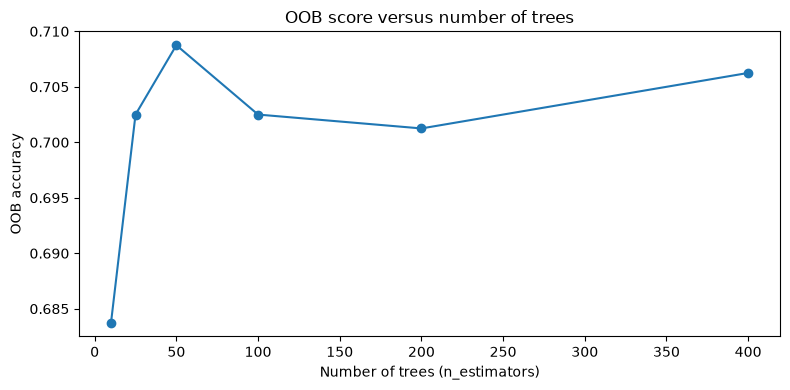

Best OOB score: 0.7088
Smallest tree count within 0.005 of best: 50
Candidate comparison uses OOB only; test metrics are intentionally withheld until final selection.


,n_estimators,max_features,oob_score,test_accuracy,test_roc_auc
0,50,sqrt,0.70875,NaN,NaN
1,50,log2,0.70875,NaN,NaN
2,50,0.5,0.70375,NaN,NaN
3,50,1.0,0.68250,NaN,NaN


FINAL MODEL: {'n_estimators': 50, 'max_features': 'sqrt'}
Final OOB score: 0.7087
Final test accuracy: 0.73
Final test ROC-AUC: 0.8315


In [14]:
# Use OOB only for model selection. The held-out test set is reserved for the final chosen model.
tree_counts = [10, 25, 50, 100, 200, 400]
oob_rows = []
for n in tree_counts:
    model = RandomForestClassifier(
        n_estimators=n, oob_score=True, bootstrap=True,
        random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    oob_rows.append({"n_estimators": n, "oob_score": model.oob_score_})

oob_table = pd.DataFrame(oob_rows)
display(oob_table)

plt.figure(figsize=(8, 4))
plt.plot(oob_table["n_estimators"], oob_table["oob_score"], marker="o")
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("OOB accuracy")
plt.title("OOB score versus number of trees")
plt.tight_layout()
plt.show()

best_oob = oob_table["oob_score"].max()
chosen_n = int(oob_table.loc[oob_table["oob_score"] >= best_oob - 0.005,
                              "n_estimators"].min())
print("Best OOB score:", round(best_oob, 4))
print("Smallest tree count within 0.005 of best:", chosen_n)

max_features_values = ["sqrt", "log2", 0.5, 1.0]
feature_rows = []
for mf in max_features_values:
    model = RandomForestClassifier(
        n_estimators=chosen_n, max_features=mf, oob_score=True,
        bootstrap=True, random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    feature_rows.append({
        "n_estimators": chosen_n,
        "max_features": mf,
        "oob_score": model.oob_score_
    })

tuning_table = pd.DataFrame(feature_rows).sort_values("oob_score", ascending=False)
tuning_table["test_accuracy"] = np.nan
tuning_table["test_roc_auc"] = np.nan
print("Candidate comparison uses OOB only; test metrics are intentionally withheld until final selection.")
display(tuning_table)

best_mf = tuning_table.iloc[0]["max_features"]
final_model = RandomForestClassifier(
    n_estimators=chosen_n, max_features=best_mf, oob_score=True,
    bootstrap=True, random_state=42, n_jobs=-1
)
final_model.fit(X_train, y_train)

final_pred = final_model.predict(X_test)
final_prob = final_model.predict_proba(X_test)[:, 1]
final_test_accuracy = accuracy_score(y_test, final_pred)
final_test_auc = roc_auc_score(y_test, final_prob)

# Report final test metrics once, after selection.
print("FINAL MODEL:", {"n_estimators": chosen_n, "max_features": best_mf})
print("Final OOB score:", round(final_model.oob_score_, 4))
print("Final test accuracy:", round(final_test_accuracy, 4))
print("Final test ROC-AUC:", round(final_test_auc, 4))

### Markdown — Task 05 logic and answer

The number of trees is selected using OOB accuracy, choosing the smallest count within 0.005 of the best OOB result. Next, `max_features` candidates are compared using OOB score. The final model is fitted after selection and its held-out test accuracy and ROC-AUC are reported once.

**Why this choice?** It balances performance and computation instead of automatically choosing 400 trees. Test columns in the candidate table are blank intentionally: filling them for every candidate would conflict with the sheet's instruction not to repeatedly use test performance for tuning.

**Real life:** Choose a production system using internal validation before evaluating it on a final independent audit.

# Task 06 — Inspect OOB predictions and uncertainty
**Stretch answer:** Individual OOB estimates can be noisy because each row may be left out of a different, limited number of trees. The overall OOB score averages across many rows and can be more stable than a single row's estimate.

In [15]:
oob_prob = final_model.oob_decision_function_[:, 1]
oob_table = X_train.copy()
oob_table["true_label"] = y_train.to_numpy()
oob_table["oob_survival_probability"] = oob_prob
oob_table["distance_from_0_5"] = np.abs(oob_prob - 0.5)

closest10 = oob_table.nsmallest(10, "distance_from_0_5")
display(closest10.drop(columns="distance_from_0_5"))

print("Final model OOB score:", round(final_model.oob_score_, 4))
print("Final model test accuracy:", round(final_test_accuracy, 4))
print("Absolute difference:", round(abs(final_model.oob_score_ - final_test_accuracy), 4))

if abs(final_model.oob_score_ - final_test_accuracy) <= 0.05:
    print("These scores are reasonably close (within 0.05), though this alone does not prove generalization.")
else:
    print("These scores differ by more than 0.05; investigate sampling variation and model behavior.")

# Stretch: estimate how many trees left each training row out, if supported by the installed version.
try:
    from sklearn.ensemble._forest import _generate_sample_indices
    counts_in_bag = np.zeros((len(final_model.estimators_), len(X_train)), dtype=bool)
    for t, estimator in enumerate(final_model.estimators_):
        sampled = _generate_sample_indices(
            estimator.random_state, len(X_train), len(X_train)
        )
        counts_in_bag[t, np.unique(sampled)] = True
    oob_tree_counts = (~counts_in_bag).sum(axis=0)
    few_oob = pd.DataFrame({
        "training_index": X_train.index,
        "oob_tree_count": oob_tree_counts,
        "oob_survival_probability": oob_prob
    }).nsmallest(5, "oob_tree_count")
    display(few_oob)
except Exception as exc:
    print("Stretch calculation unavailable in this scikit-learn version:", exc)

,pclass,sex_male,age,sibsp,parch,fare,true_label,oob_survival_probability
554,3,0,17.5,0,0,6.46,0,0.5
704,1,1,41.7,0,0,51.86,1,0.5
912,3,1,41.4,0,0,7.07,0,0.5
994,2,1,11.1,0,0,30.67,1,0.5
398,3,1,5.8,0,2,13.50,0,0.5
225,2,1,29.2,0,0,49.08,1,0.5
117,1,1,37.1,0,0,69.84,0,0.5
703,1,1,34.6,0,2,52.16,0,0.5
614,3,0,18.8,0,0,6.55,0,0.5
94,3,0,27.2,1,0,9.08,1,0.5


Final model OOB score: 0.7087
Final model test accuracy: 0.73
Absolute difference: 0.0212
These scores are reasonably close (within 0.05), though this alone does not prove generalization.
Stretch calculation unavailable in this scikit-learn version: _generate_sample_indices() missing 1 required positional argument: 'sample_weight'


### Markdown — Task 06 logic and answer

`oob_decision_function_[:, 1]` contains each training passenger's OOB survival probability. Sorting by distance from 0.5 displays the ten least decisive cases. Compare the model's OOB score with final test accuracy; the 0.05 threshold is a simple descriptive rule, not a formal statistical test. The stretch code estimates how many trees omitted each training row, if the installed scikit-learn version supports the internal helper.

**Why 0.5 is uncertain:** the model assigns similar support to both classes.

**Real life:** A bank risk score near its decision boundary may require human review rather than an automatic decision.

# Task 07 — Catch a misleading feature-importance result
**Lookup / concept answers:** Impurity importance adds up impurity reductions credited to a feature inside trees. Permutation importance measures how much held-out score drops when a feature is shuffled. High-cardinality features have many possible split points and can receive misleadingly high impurity importance.

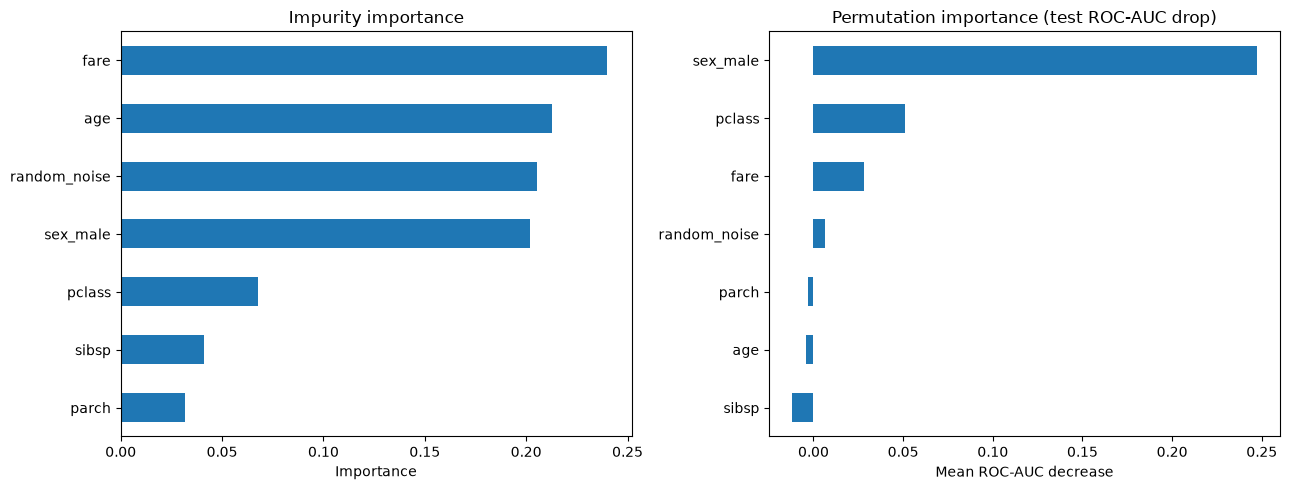

random_noise impurity importance: 0.205187 | rank: 3
random_noise permutation importance: 0.006326 | rank: 4


In [16]:
rng_noise = np.random.default_rng(2026)
X_train_noise = X_train.copy()
X_test_noise = X_test.copy()
X_train_noise["random_noise"] = rng_noise.normal(size=len(X_train_noise))
X_test_noise["random_noise"] = rng_noise.normal(size=len(X_test_noise))

noise_model = RandomForestClassifier(
    n_estimators=300, random_state=42, n_jobs=-1
)
noise_model.fit(X_train_noise, y_train)

impurity = pd.Series(
    noise_model.feature_importances_, index=X_train_noise.columns
).sort_values()

perm = permutation_importance(
    noise_model, X_test_noise, y_test,
    scoring="roc_auc", n_repeats=30, random_state=42, n_jobs=-1
)
permutation = pd.Series(
    perm.importances_mean, index=X_test_noise.columns
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
impurity.plot(kind="barh", ax=axes[0])
axes[0].set_title("Impurity importance")
axes[0].set_xlabel("Importance")
permutation.plot(kind="barh", ax=axes[1])
axes[1].set_title("Permutation importance (test ROC-AUC drop)")
axes[1].set_xlabel("Mean ROC-AUC decrease")
plt.tight_layout()
plt.show()

imp_rank = int(impurity.rank(ascending=False, method="min")["random_noise"])
perm_rank = int(permutation.rank(ascending=False, method="min")["random_noise"])
print("random_noise impurity importance:", round(impurity["random_noise"], 6),
      "| rank:", imp_rank)
print("random_noise permutation importance:", round(permutation["random_noise"], 6),
      "| rank:", perm_rank)

### Markdown — Task 07 logic and answer

A deliberately random feature is added to both training and test data. Impurity importance is taken from the fitted forest; permutation importance shuffles each test feature repeatedly and measures the ROC-AUC change. Report the printed rank and score for `random_noise`.

Complete using your results:

> For this dataset, I would not report impurity importance alone because it can favor features with many possible split points and does not directly measure the loss in held-out predictive performance. I would compare it with permutation importance and explain any differences.

The rankings can disagree because the methods measure different things; correlated predictors can also mask each other's contribution.

**Real life:** A dashboard metric may look influential inside a system but may not meaningfully improve real-world outcomes when disrupted.

# Task 08 — Explain two model relationships with PDPs
**Lookup / concept answer:** A Partial Dependence Plot (PDP) changes one selected feature and averages model predictions over the remaining observations. It shows model behavior, not proof that changing the feature causes an outcome.

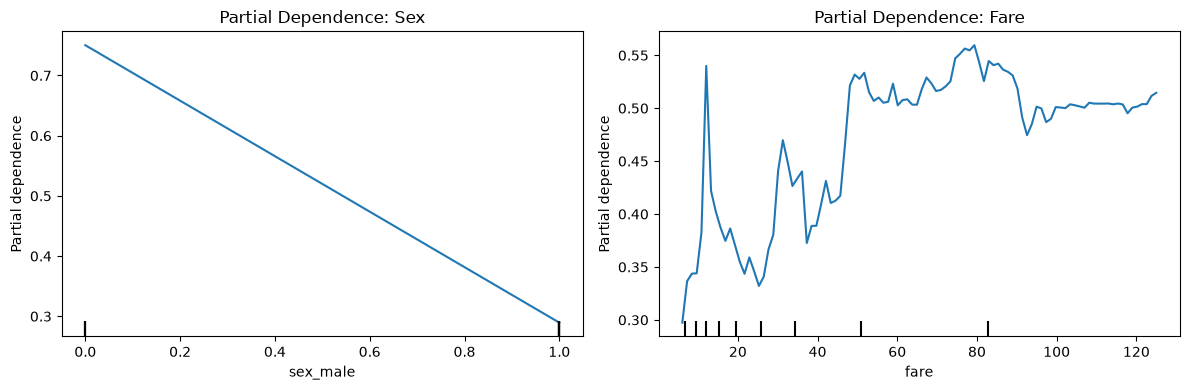

In [22]:

# Convert integer features to float for PDP compatibility
X_train_pdp = X_train.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

PartialDependenceDisplay.from_estimator(
    final_model,
    X_train_pdp,
    ["sex_male"],
    ax=axes[0],
    kind="average"
)
axes[0].set_title("Partial Dependence: Sex")

PartialDependenceDisplay.from_estimator(
    final_model,
    X_train_pdp,
    ["fare"],
    ax=axes[1],
    kind="average"
)
axes[1].set_title("Partial Dependence: Fare")

plt.tight_layout()
plt.show()


### Markdown — Task 08 logic and answer

**`sex_male`:** Describe whether the average predicted survival probability is higher for 0 or 1, and quantify the direction from the plot. Since this is a binary feature, the relationship appears as a comparison or jump between two values.

**`fare`:** Describe whether the curve rises, falls, bends, or plateaus across the observed fare range. Base the description on the plotted curve, not on an assumed result.

Neither plot proves causation: the data are observational and other factors may explain the relationship. Correlated features and unrealistic combinations (for example, assigning a very unusual fare to every passenger while holding all other features fixed) can make PDP values misleading.

**Real life:** A PDP is like a controlled “what if” calculation inside a prediction model, not a real-world experiment.

# Task 09 — Write a one-page model recommendation memo
**Lookup / concept answer:** A useful memo reports objective, model choice, metrics, evidence-backed findings, risks, and a next step. Do not make causal claims from predictive importance.

In [18]:
# Create a memo using results generated by this notebook.
memo = f'''# Titanic Random Forest Model Recommendation

## Objective
Predict Titanic passenger survival (`survived`) using pclass, sex_male, age, sibsp, parch, and fare from the supplied Titanic dataset.

## Model choice
A Random Forest is a suitable baseline because it combines many decision trees, uses bootstrap samples and random feature subsets, and can reduce the variance of an individual tree. It can model nonlinear patterns without requiring feature scaling.

## Evaluation
- Final test accuracy: {final_test_accuracy:.3f}
- Final test ROC-AUC: {final_test_auc:.3f}
- Final model OOB score: {final_model.oob_score_:.3f}
- Stability across 25 bootstrap training samples: consult the Task 04 mean and standard deviation table before making a claim.

## Key findings
Use the Task 07 permutation-importance ranking and Task 08 PDPs to state two patterns supported by the actual plots. Do not claim that a feature causes survival.

## Risks and limitations
The dataset is historical and may not represent other populations. Missing-value imputation can affect results. Correlation is not causation, and importance rankings can be biased or unstable. A single train/test split has sampling uncertainty, and predictions raise fairness and ethical interpretation concerns.

## Recommendation
Use this Random Forest as a baseline only. Next, run cross-validation on the training set and compare it with logistic regression or gradient boosting; assess probability calibration before using predicted probabilities for decisions.
'''
with open("Day27_Model_Memo.md", "w", encoding="utf-8") as f:
    f.write(memo)
print("Created Day27_Model_Memo.md")
print(memo)

Created Day27_Model_Memo.md
# Titanic Random Forest Model Recommendation

## Objective
Predict Titanic passenger survival (`survived`) using pclass, sex_male, age, sibsp, parch, and fare from the supplied Titanic dataset.

## Model choice
A Random Forest is a suitable baseline because it combines many decision trees, uses bootstrap samples and random feature subsets, and can reduce the variance of an individual tree. It can model nonlinear patterns without requiring feature scaling.

## Evaluation
- Final test accuracy: 0.730
- Final test ROC-AUC: 0.831
- Final model OOB score: 0.709
- Stability across 25 bootstrap training samples: consult the Task 04 mean and standard deviation table before making a claim.

## Key findings
Use the Task 07 permutation-importance ranking and Task 08 PDPs to state two patterns supported by the actual plots. Do not claim that a feature causes survival.

## Risks and limitations
The dataset is historical and may not represent other populations. Missing-va

### Markdown — Task 09 logic and answer

The code writes `Day27_Model_Memo.md` with the required headings and metrics. The memo leaves the stability claim tied to Task 04 and asks you to use the actual importance/PDP plots for the findings, rather than inventing them. Review the generated memo after running the notebook and ensure it remains under 500 words.

**Real life:** A technical recommendation memo helps a manager decide whether a model is ready for a pilot and what validation is still needed.

# Final Markdown cell — What I learned

- Bootstrap sampling creates different training samples by drawing rows with replacement.
- Bagging combines multiple trees to reduce prediction variance.
- Random Forests add random feature selection to increase tree diversity.
- OOB evaluation supports model selection without using the held-out test set for every decision.
- Feature importance and PDPs describe model behavior but do not establish causation.